In [28]:
from __future__ import annotations

import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix


# ---------- Reproducibility ----------
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

tf.config.experimental.enable_op_determinism()


# ---------- Kaggle output locations ----------
WORKING_DIR = Path("/kaggle/working")
FIGURES_DIR = WORKING_DIR / "figures"
METRICS_DIR = WORKING_DIR / "metrics"
MODELS_DIR = WORKING_DIR / "models"

for directory in (FIGURES_DIR, METRICS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)


# ---------- Experiment configuration ----------
CLASS_NAMES = ("glioma", "meningioma", "notumor", "pituitary")
CLASS_TO_INDEX = {class_name: index for index, class_name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

IMG_SIZE = (299, 299)
BATCH_SIZE = 16
MAX_EPOCHS = 20
LEARNING_RATE = 1e-3

EXPERIMENT_NAME = "mri_xception_frozen_baseline"

CHECKPOINT_PATH = MODELS_DIR / f"{EXPERIMENT_NAME}_best.keras"
CONFIG_PATH = METRICS_DIR / f"{EXPERIMENT_NAME}_config.json"

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU devices: {tf.config.list_physical_devices('GPU')}")
print(f"Input size: {IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Classes: {CLASS_NAMES}")

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Input size: (299, 299)
Batch size: 16
Classes: ('glioma', 'meningioma', 'notumor', 'pituitary')


In [29]:
KAGGLE_INPUT_DIR = Path("/kaggle/input")


def find_mri_root() -> Path:
    expected_classes = set(CLASS_NAMES)

    for training_dir in KAGGLE_INPUT_DIR.rglob("Training"):
        candidate_root = training_dir.parent
        testing_dir = candidate_root / "Testing"

        class_folders = {
            folder.name
            for folder in training_dir.iterdir()
            if folder.is_dir()
        }

        if testing_dir.is_dir() and expected_classes.issubset(class_folders):
            return candidate_root

    raise FileNotFoundError(
        "Could not find MRI Training/Testing folders in Kaggle inputs."
    )


def find_split_csv() -> Path:
    matches = list(KAGGLE_INPUT_DIR.rglob("mri_train_val_split.csv"))

    if len(matches) != 1:
        raise FileNotFoundError(
            "Expected exactly one mri_train_val_split.csv Kaggle input."
        )

    return matches[0]


MRI_ROOT = find_mri_root()
SPLIT_CSV_PATH = find_split_csv()

split_metadata = pd.read_csv(SPLIT_CSV_PATH)

print(f"MRI root: {MRI_ROOT}")
print(f"Split CSV: {SPLIT_CSV_PATH}")
print(f"Split rows: {len(split_metadata):,}")

display(split_metadata.head())

MRI root: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
Split CSV: /kaggle/input/datasets/hamody0/mri-train-val-split/mri_train_val_split.csv
Split rows: 5,600


,filepath,class,split,filename,sha256
0,data/raw/mri/Training/glioma/Tr-gl_1.jpg,glioma,train,Tr-gl_1.jpg,5ac3fbd85891bf49b4c337ea49d7f382698f960c046a3d...
1,data/raw/mri/Training/glioma/Tr-gl_100.jpg,glioma,train,Tr-gl_100.jpg,544aa9e1829e61d95d5c2b68863dd2bd98bb44eaa19822...
2,data/raw/mri/Training/glioma/Tr-gl_1000.jpg,glioma,train,Tr-gl_1000.jpg,88b2a7e2adcc2f9b23ef908bb3063f2585068b350ab86a...
3,data/raw/mri/Training/glioma/Tr-gl_1001.jpg,glioma,train,Tr-gl_1001.jpg,48a0ad607d04b380ae7c8a40558677f63351ea6696b706...
4,data/raw/mri/Training/glioma/Tr-gl_1002.jpg,glioma,train,Tr-gl_1002.jpg,dd00d89233f404ed4f8b4787b151a68befd2cc3efe5da6...


In [30]:
def resolve_kaggle_image_path(filepath: str) -> Path:
    project_relative = Path(filepath)
    expected_prefix = Path("data") / "raw" / "mri"

    try:
        mri_relative = project_relative.relative_to(expected_prefix)
    except ValueError as error:
        raise ValueError(f"Unexpected split path: {filepath}") from error

    return MRI_ROOT / mri_relative


split_metadata = split_metadata.copy()
split_metadata["image_path"] = split_metadata["filepath"].map(
    resolve_kaggle_image_path
)

split_metadata["label"] = split_metadata["class"].map(CLASS_TO_INDEX)

assert len(split_metadata) == 5600
assert split_metadata["filepath"].nunique() == 5600
assert split_metadata["label"].notna().all()
assert set(split_metadata["split"]) == {"train", "validation"}

missing_paths = split_metadata.loc[
    ~split_metadata["image_path"].map(Path.exists)
]

assert missing_paths.empty, "Some split images do not exist."

testing_paths = split_metadata["image_path"].map(
    lambda path: "Testing" in path.parts
)

assert not testing_paths.any(), "Testing images must never enter Phase 3."

train_metadata = split_metadata.loc[
    split_metadata["split"].eq("train")
].reset_index(drop=True)

validation_metadata = split_metadata.loc[
    split_metadata["split"].eq("validation")
].reset_index(drop=True)

print(f"Training images: {len(train_metadata):,}")
print(f"Validation images: {len(validation_metadata):,}")
print(f"Testing paths referenced: {testing_paths.sum()}")

print("\nClass counts:")
print(split_metadata.groupby(["split", "class"]).size())

Training images: 4,480
Validation images: 1,120
Testing paths referenced: 0

Class counts:
split       class     
train       glioma        1120
            meningioma    1120
            notumor       1120
            pituitary     1120
validation  glioma         280
            meningioma     280
            notumor        280
            pituitary      280
dtype: int64


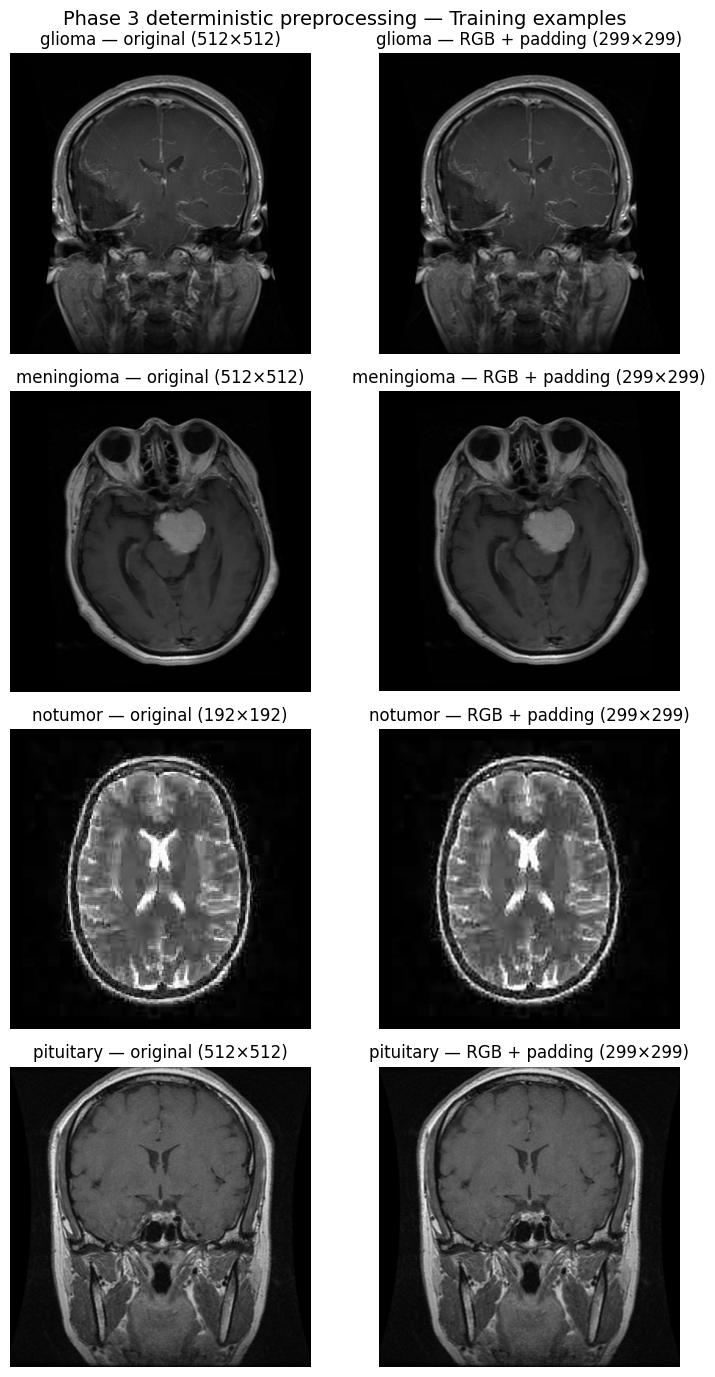

Saved: /kaggle/working/figures/mri_phase3_preprocessing_examples.png


In [31]:
def load_rgb_image(image_path: str | Path) -> Image.Image:
    """Loads every source mode as RGB."""
    with Image.open(image_path) as image:
        return image.convert("RGB")


def preprocess_pil_image(
    image_path: str | Path,
    target_size: tuple[int, int] = IMG_SIZE,
) -> Image.Image:
    """
    Deterministic preprocessing:
    Pillow RGB conversion -> preserve aspect ratio -> black padding.
    """
    image = load_rgb_image(image_path)

    return ImageOps.pad(
        image,
        size=target_size,
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0),
        centering=(0.5, 0.5),
    )


visual_examples = (
    train_metadata
    .sort_values(["class", "filepath"])
    .groupby("class", sort=True)
    .head(1)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(NUM_CLASSES, 2, figsize=(8, 14))

for row_index, (_, row) in enumerate(visual_examples.iterrows()):
    original = load_rgb_image(row["image_path"])
    processed = preprocess_pil_image(row["image_path"])

    assert processed.mode == "RGB"
    assert processed.size == IMG_SIZE

    axes[row_index, 0].imshow(original)
    axes[row_index, 0].set_title(
        f"{row['class']} — original ({original.width}×{original.height})"
    )
    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(processed)
    axes[row_index, 1].set_title(
        f"{row['class']} — RGB + padding ({processed.width}×{processed.height})"
    )
    axes[row_index, 1].axis("off")

fig.suptitle("Phase 3 deterministic preprocessing — Training examples", fontsize=14)
fig.tight_layout()

preprocessing_figure_path = FIGURES_DIR / "mri_phase3_preprocessing_examples.png"
fig.savefig(preprocessing_figure_path, dpi=150, bbox_inches="tight")

plt.show()
plt.close(fig)

print(f"Saved: {preprocessing_figure_path}")

In [32]:
def pil_preprocess_for_tensorflow(path_bytes) -> np.ndarray:
    """
    Runs Pillow preprocessing inside tf.numpy_function.

    Important:
    - Explicitly calls convert('RGB')
    - Does not augment
    - Returns pixels in [0, 255]
    - Xception preprocessing is applied afterward by TensorFlow
    """
    image_path = Path(path_bytes.decode("utf-8"))

    processed_image = preprocess_pil_image(image_path)
    image_array = np.asarray(processed_image, dtype=np.float32)

    return image_array


def load_preprocess_tensorflow(path, label):
    image = tf.numpy_function(
        func=pil_preprocess_for_tensorflow,
        inp=[path],
        Tout=tf.float32,
    )

    image.set_shape((IMG_SIZE[0], IMG_SIZE[1], 3))

    # Correct Xception ImageNet preprocessing: scales input to [-1, 1].
    image = preprocess_input(image)

    label = tf.cast(label, tf.int32)

    return image, label


def build_dataset(
    metadata: pd.DataFrame,
    training: bool,
) -> tf.data.Dataset:
    paths = metadata["image_path"].astype(str).to_numpy()
    labels = metadata["label"].astype(np.int32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    options = tf.data.Options()
    options.experimental_deterministic = True
    dataset = dataset.with_options(options)

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(metadata),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_preprocess_tensorflow,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_dataset = build_dataset(train_metadata, training=True)
validation_dataset = build_dataset(validation_metadata, training=False)

images_batch, labels_batch = next(iter(train_dataset))

print(f"Image batch shape: {images_batch.shape}")
print(f"Label batch shape: {labels_batch.shape}")
print(f"Pixel range after Xception preprocessing: "
      f"{tf.reduce_min(images_batch).numpy():.3f} to "
      f"{tf.reduce_max(images_batch).numpy():.3f}")

Image batch shape: (16, 299, 299, 3)
Label batch shape: (16,)
Pixel range after Xception preprocessing: -1.000 to 1.000


In [33]:
keras.backend.clear_session()

backbone = Xception(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
)

# Phase 3 requirement: frozen ImageNet backbone.
backbone.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    name="mri_image",
)

# training=False keeps Xception BatchNormalization behavior fixed.
x = backbone(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.20, name="dropout")(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification_output",
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name=EXPERIMENT_NAME,
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

model.summary()

print(f"\nBackbone trainable: {backbone.trainable}")
print(f"Total parameters: {model.count_params():,}")
print(
    f"Trainable parameters: "
    f"{sum(np.prod(variable.shape) for variable in model.trainable_weights):,}"
)

Model: "mri_xception_frozen_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_image (InputLayer)          │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,869,676 (79.61 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 20,861,480 (79.58 MB)


Backbone trainable: False
Total parameters: 20,869,676
Trainable parameters: 8,196


In [34]:
experiment_config = {
    "experiment_name": EXPERIMENT_NAME,
    "random_state": RANDOM_STATE,
    "architecture": "Xception",
    "pretrained_weights": "ImageNet",
    "backbone_frozen": True,
    "input_size": list(IMG_SIZE),
    "preprocessing": (
        "Pillow convert('RGB') -> aspect-ratio-preserving resize "
        "-> black padding -> Xception preprocess_input"
    ),
    "train_augmentation": "None",
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "loss": "SparseCategoricalCrossentropy",
    "classes": list(CLASS_NAMES),
    "train_images": len(train_metadata),
    "validation_images": len(validation_metadata),
    "test_images_used": 0,
    "known_limitation": (
        "The standard validation split contains known exact duplicate groups "
        "crossing train and validation; validation results may be optimistic."
    ),
}

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(experiment_config, file, indent=2)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=CHECKPOINT_PATH,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

print(f"Configuration saved: {CONFIG_PATH}")
print(f"Best-model checkpoint: {CHECKPOINT_PATH}")

Configuration saved: /kaggle/working/metrics/mri_xception_frozen_baseline_config.json
Best-model checkpoint: /kaggle/working/models/mri_xception_frozen_baseline_best.keras


In [35]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=MAX_EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.6771 - loss: 0.8440
Epoch 1: val_loss improved from None to 0.47276, saving model to /kaggle/working/models/mri_xception_frozen_baseline_best.keras

Epoch 1: finished saving model to /kaggle/working/models/mri_xception_frozen_baseline_best.keras
280/280 ━━━━━━━━━━━━━━━━━━━━ 111s 372ms/step - accuracy: 0.7725 - loss: 0.6336 - val_accuracy: 0.8286 - val_loss: 0.4728 - learning_rate: 0.0010
Epoch 2/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - accuracy: 0.8623 - loss: 0.4184
Epoch 2: val_loss improved from 0.47276 to 0.38858, saving model to /kaggle/working/models/mri_xception_frozen_baseline_best.keras

Epoch 2: finished saving model to /kaggle/working/models/mri_xception_frozen_baseline_best.keras
280/280 ━━━━━━━━━━━━━━━━━━━━ 101s 361ms/step - accuracy: 0.8708 - loss: 0.3933 - val_accuracy: 0.8607 - val_loss: 0.3886 - learning_rate: 0.0010
Epoch 3/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.8855 - loss

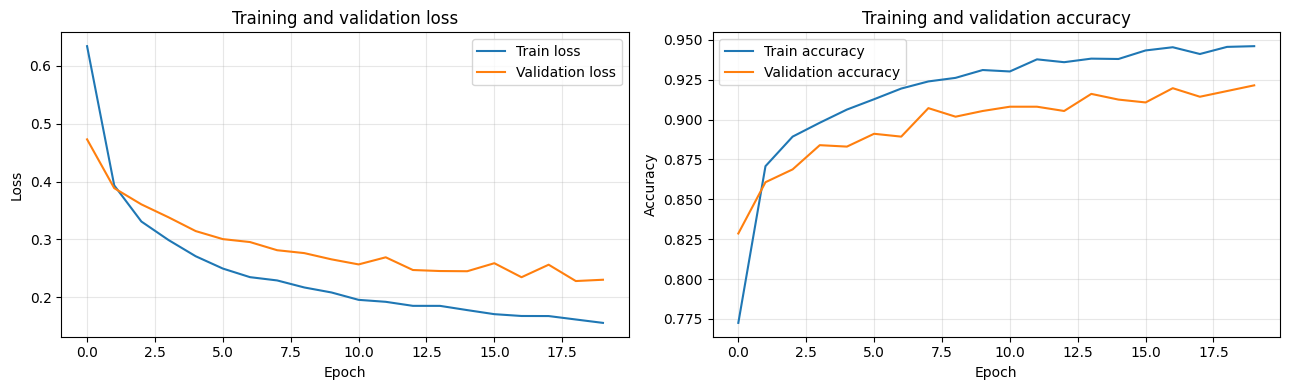

Saved history: /kaggle/working/metrics/mri_xception_frozen_baseline_history.csv
Saved curves: /kaggle/working/figures/mri_phase3_training_curves.png


In [36]:
history_frame = pd.DataFrame(history.history)
history_csv_path = METRICS_DIR / f"{EXPERIMENT_NAME}_history.csv"
history_frame.to_csv(history_csv_path, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Train loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["accuracy"], label="Train accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Training and validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()

training_curves_path = FIGURES_DIR / "mri_phase3_training_curves.png"
fig.savefig(training_curves_path, dpi=150, bbox_inches="tight")

plt.show()
plt.close(fig)

print(f"Saved history: {history_csv_path}")
print(f"Saved curves: {training_curves_path}")

70/70 ━━━━━━━━━━━━━━━━━━━━ 22s 296ms/step
              precision    recall  f1-score   support

      glioma       0.94      0.91      0.92       280
  meningioma       0.87      0.83      0.85       280
     notumor       0.96      0.98      0.97       280
   pituitary       0.90      0.95      0.93       280

    accuracy                           0.92      1120
   macro avg       0.92      0.92      0.92      1120
weighted avg       0.92      0.92      0.92      1120



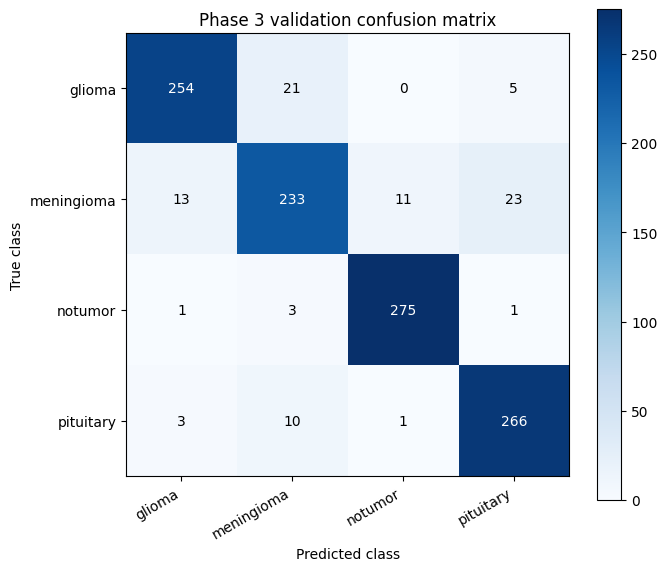

Saved validation metrics: /kaggle/working/metrics/mri_xception_frozen_baseline_validation_metrics.csv
Saved confusion matrix: /kaggle/working/figures/mri_phase3_confusion_matrix.png


In [37]:
# Reload the best validation-loss checkpoint.
best_model = keras.models.load_model(CHECKPOINT_PATH)

validation_probabilities = best_model.predict(
    validation_dataset,
    verbose=1,
)

validation_predictions = np.argmax(validation_probabilities, axis=1)
validation_true_labels = validation_metadata["label"].to_numpy()

assert len(validation_predictions) == len(validation_true_labels)

classification_metrics = classification_report(
    validation_true_labels,
    validation_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

metrics_frame = (
    pd.DataFrame(classification_metrics)
    .transpose()
    .reset_index()
    .rename(columns={"index": "metric_or_class"})
)

metrics_csv_path = METRICS_DIR / f"{EXPERIMENT_NAME}_validation_metrics.csv"
metrics_frame.to_csv(metrics_csv_path, index=False)

print(
    classification_report(
        validation_true_labels,
        validation_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0,
    )
)

confusion = confusion_matrix(
    validation_true_labels,
    validation_predictions,
    labels=list(range(NUM_CLASSES)),
)

fig, axis = plt.subplots(figsize=(7, 6))

image = axis.imshow(confusion, cmap="Blues")
fig.colorbar(image, ax=axis)

axis.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Predicted class",
    ylabel="True class",
    title="Phase 3 validation confusion matrix",
)

plt.setp(axis.get_xticklabels(), rotation=30, ha="right")

for row_index in range(NUM_CLASSES):
    for column_index in range(NUM_CLASSES):
        axis.text(
            column_index,
            row_index,
            str(confusion[row_index, column_index]),
            ha="center",
            va="center",
            color="white" if confusion[row_index, column_index] > confusion.max() / 2 else "black",
        )

fig.tight_layout()

confusion_matrix_path = FIGURES_DIR / "mri_phase3_confusion_matrix.png"
fig.savefig(confusion_matrix_path, dpi=150, bbox_inches="tight")

plt.show()
plt.close(fig)

print(f"Saved validation metrics: {metrics_csv_path}")
print(f"Saved confusion matrix: {confusion_matrix_path}")

In [38]:
best_epoch = int(np.argmin(history.history["val_loss"])) + 1

report = f"""MRI PHASE 3 — FROZEN XCEPTION BASELINE
=====================================

Experiment:
Name: {EXPERIMENT_NAME}
Random seed: {RANDOM_STATE}

Data:
Training images: {len(train_metadata)}
Validation images: {len(validation_metadata)}
Testing images used: 0

Split:
Source: Phase 2 stratified split
Training/validation overlap: 0 paths
Important limitation:
The standard split includes known exact duplicate groups across training
and validation. Validation metrics may therefore be optimistic.

Preprocessing:
RGB conversion: Pillow image.convert("RGB")
Resize: aspect-ratio-preserving resize with black padding
Input size: {IMG_SIZE}
Model preprocessing: Xception preprocess_input
Training augmentation: none
Validation preprocessing: deterministic

Model:
Architecture: Xception
Weights: ImageNet
Backbone frozen: YES
Classification head: GlobalAveragePooling2D -> Dropout(0.20) -> Dense(4, softmax)

Training:
Optimizer: Adam
Initial learning rate: {LEARNING_RATE}
Batch size: {BATCH_SIZE}
Maximum epochs: {MAX_EPOCHS}
Best validation-loss epoch: {best_epoch}

Best observed validation metrics:
Validation loss: {min(history.history["val_loss"]):.4f}
Validation accuracy: {max(history.history["val_accuracy"]):.4f}

Final test evaluation:
NOT PERFORMED
The original Testing directory remains reserved for Phase 5.
"""

report_path = METRICS_DIR / "mri_phase3_report.txt"
report_path.write_text(report, encoding="utf-8")

print(report)
print(f"Saved report: {report_path}")

MRI PHASE 3 — FROZEN XCEPTION BASELINE

Experiment:
Name: mri_xception_frozen_baseline
Random seed: 42

Data:
Training images: 4480
Validation images: 1120
Testing images used: 0

Split:
Source: Phase 2 stratified split
Training/validation overlap: 0 paths
Important limitation:
The standard split includes known exact duplicate groups across training
and validation. Validation metrics may therefore be optimistic.

Preprocessing:
RGB conversion: Pillow image.convert("RGB")
Resize: aspect-ratio-preserving resize with black padding
Input size: (299, 299)
Model preprocessing: Xception preprocess_input
Training augmentation: none
Validation preprocessing: deterministic

Model:
Architecture: Xception
Weights: ImageNet
Backbone frozen: YES
Classification head: GlobalAveragePooling2D -> Dropout(0.20) -> Dense(4, softmax)

Training:
Optimizer: Adam
Initial learning rate: 0.001
Batch size: 16
Maximum epochs: 20
Best validation-loss epoch: 19

Best observed validation metrics:
Validation loss: 0.2